In [2]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from sklearn.linear_model import LinearRegression
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import numpy as np
import pandas

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression


In [3]:
DataToFit = np.transpose(np.asarray(np.genfromtxt('deltat5e8forHenry.csv',delimiter=',',skip_header=1)))
# 6 = logM
logMIndex = 6
# 7 = logL
logLIndex = 7
# 9 = logR
logRIndex = 9
# 14 = Fundamental period from Trabucchi model
P0Index = 13
# 15 = logP0 from Trabucchi model
logP0Index = 12
# 15 = Overtone period from Trabucchi model
P1Index=15
# 15 = logP1 from COLIBRI model
logP1Index=16
# 17 = Pulsation Mode
ModeIndex=17
# 25 = log(C/O)
logCORatioIndex=25

In [4]:
def PulsationModeSort (input_array):
    FundamentalPulsators = []
    OvertonePulsators = []
    i = 0
    while i < len(input_array[ModeIndex]):
        if input_array[ModeIndex][i] == 0:
            FundamentalPulsators.append(i)
        if input_array[ModeIndex][i] == 1:
            OvertonePulsators.append(i)
        i += 1
    FundamentalModeStars = np.transpose(input_array.transpose()[FundamentalPulsators])
    FirstOvertoneModeStars = np.transpose(input_array.transpose()[OvertonePulsators])
    return FundamentalModeStars, FirstOvertoneModeStars

def CompositionSort (input_array):
    ORichStarsIndices = []
    CRichStarsIndices = []
    i = 0
    while i < len(input_array[logCORatioIndex]):
        if input_array[logCORatioIndex][i] < 0:
            ORichStarsIndices.append(i)
        if input_array[logCORatioIndex][i] > 0:
            CRichStarsIndices.append(i)
        i += 1
    ORichStars = np.transpose(input_array.transpose()[ORichStarsIndices])
    CRichStars = np.transpose(input_array.transpose()[CRichStarsIndices])
    return ORichStars, CRichStars

In [5]:
def MassSort (input_array):
    logMLT005 = []
    logMGT005 = []
    i = 0
    while i < len(input_array[logMIndex]):
        if input_array[logMIndex][i] <= 0.05: # For all stars with logM < 0.05
            logMLT005.append(i)
        if input_array[logMIndex][i] > -0.05 and input_array[6][i] <= 0.4 : # For all stars with logM > -0.05 - yes, there needs to be overlap!
            logMGT005.append(i)
        #if input_array[logMIndex][i] > 0.4:
            #print("Star", i, "of mass",10**(input_array[6][i]),"cut")
        i += 1
    #LowMassStars = np.transpose(input_array.transpose()[logMLT005])
    #HighMassStars = np.transpose(input_array.transpose()[logMGT005])
    return logMLT005, logMGT005

def MassFilter (Mass_Data):
    logMListArray = []
    i = 0
    while i<len(Mass_Data):
        if Mass_Data[i] < 0.4:
            logMListArray.append(i)
        i += 1
    return logMListArray

In [6]:
def NormalizeLogValue (input_array, lower_limit, upper_limit):
    # Rescale an input value (an NP array-like variable) such that something that runs lower_limit < logValue < upper_limit runs from 0 to 1
    # Rescale the pulsation periods such that 1.8 < log P < 2.8 runs from 0 to 1
    NormalizedValues = (input_array - lower_limit)/(upper_limit - lower_limit)
    return NormalizedValues    

In [7]:
P0Stars, P1Stars = PulsationModeSort(DataToFit)
LowLogMToFitStars, HighLogMToFitStars = MassSort(DataToFit)
#ORichP0Stars, CRichP0Stars = CompositionSort(P0Stars)
#ORichP1Stars, CRichP1Stars = CompositionSort(P1Stars)
#logMData = DataToFit[logMIndex]
#logMLT005Data = DataToFit[logMIndex][LowLogMToFitStars]
#logMMGT005Data = DataToFit[logMIndex][HighLogMToFitStars]
#logRData = DataToFit[logRIndex]
#logRMLT005Data = DataToFit[logRIndex][LowLogMToFitStars]
#logRMGT005Data = DataToFit[logRIndex][HighLogMToFitStars]
#logLData = DataToFit[logLIndex]
#logLLT005Data = DataToFit[logLIndex][LowLogMToFitStars]
#logLMGT005Data = DataToFit[logLIndex][HighLogMToFitStars]

In [8]:
NormalizedlogP0 = NormalizeLogValue(P0Stars[logP0Index], 1.8, 2.8)
NormalizedlogP1 = NormalizeLogValue(P1Stars[logP1Index], 1.8, 2.8)
NormalizedlogM_Funds = NormalizeLogValue(P0Stars[logMIndex], -0.3, 0.4)
NormalizedlogL_Funds = NormalizeLogValue(P0Stars[logLIndex], 3, 4.2)
NormalizedlogM_Overtones = NormalizeLogValue(P1Stars[logMIndex], -0.3, 0.4)
NormalizedlogL_Overtones = NormalizeLogValue(P1Stars[logLIndex], 3, 4.2)

FundamentalPulsatorsArray = np.asarray([NormalizedlogP0, NormalizedlogM_Funds, NormalizedlogL_Funds, P0Stars[logRIndex]])
OveronePulsatorsArray = np.asarray([NormalizedlogP1, NormalizedlogM_Overtones, NormalizedlogL_Overtones, P1Stars[logRIndex]])

In [9]:
len(np.transpose(FundamentalPulsatorsArray))

357

In [10]:
FundamentalPulsatorsArray


array([[0.1749    , 0.1767    , 0.1613    , ..., 0.9737    , 1.0749    ,
        1.175     ],
       [0.15555714, 0.17265714, 0.23075714, ..., 0.9118    , 0.88444286,
        0.84544286],
       [0.14083333, 0.14583333, 0.16166667, ..., 1.03      , 1.04083333,
        1.05083333],
       [1.9967    , 2.0029    , 2.013     , ..., 2.6004    , 2.6397    ,
        2.6747    ]])

In [11]:
def LimitNormalizedLogValue (input_array, lower_limit, upper_limit):
    # Restrict the normalized log value to be between lower_limit and upper_limit on each dimension
    working_array = np.transpose(input_array)
    rows_to_remove = []
    indx_1 = 0
    while indx_1 < 3:
        gt1 = np.where(FundamentalPulsatorsArray[indx_1]>1)
        lt0 = np.where(FundamentalPulsatorsArray[indx_1]<0)
        rows_to_remove.append(gt1[0].tolist())
        rows_to_remove.append(lt0[0].tolist())
        indx_1 +=1
    rows_to_remove = [y for x in rows_to_remove for y in x] # Flattens list
    rows_to_remove_final = []
    [rows_to_remove_final.append(x) for x in rows_to_remove if x not in rows_to_remove_final] 
    rows_to_remove_final.sort()
    print (rows_to_remove_final)
    return np.asarray(rows_to_remove_final)

In [12]:
P0RowsToRemove = LimitNormalizedLogValue (FundamentalPulsatorsArray, 0, 1)

[208, 219, 223, 233, 236, 237, 241, 242, 245, 247, 248, 250, 256, 260, 261, 262, 263, 269, 270, 272, 275, 277, 287, 292, 294, 295, 298, 303, 305, 308, 309, 312, 315, 318, 323, 324, 326, 329, 330, 335, 339, 340, 341, 342, 343, 344, 345, 349, 350, 351, 352, 353, 354, 355, 356]


In [13]:
np.transpose(np.transpose(P0Stars)[P0RowsToRemove])

array([[ 3.0000e-03,  3.0000e-03,  3.0000e-03, ...,  3.0000e-03,
         3.0000e-03,  3.0000e-03],
       [-7.0993e-01, -7.0993e-01, -7.0993e-01, ..., -7.0993e-01,
        -7.0993e-01, -7.0993e-01],
       [ 9.1761e+00,  9.3010e+00,  9.3010e+00, ...,  8.6990e+00,
         8.6990e+00,  8.6990e+00],
       ...,
       [ 8.8160e-01,  3.3144e-01,  3.2956e-01, ..., -3.5754e-02,
         6.4715e-02,  1.5595e-01],
       [ 1.6190e-02,  6.1750e-03,  6.1580e-03, ...,  4.0780e-03,
         4.4000e-03,  4.7680e-03],
       [-1.7908e+00, -2.2094e+00, -2.2106e+00, ..., -2.3896e+00,
        -2.3565e+00, -2.3217e+00]])

In [14]:
LimitedFundamentalPulsatorArray = np.delete(P0Stars,P0RowsToRemove,1)

In [15]:
LimitedFundamentalPulsatorArray

array([[ 3.0000e-03,  3.0000e-03,  3.0000e-03, ...,  3.0000e-03,
         3.0000e-03,  3.0000e-03],
       [-7.0993e-01, -7.0993e-01, -7.0993e-01, ..., -7.0993e-01,
        -7.0993e-01, -7.0993e-01],
       [ 9.8451e+00,  9.8129e+00,  9.7781e+00, ...,  8.6990e+00,
         8.6990e+00,  8.6990e+00],
       ...,
       [-4.7812e-01, -4.8286e-01, -4.8790e-01, ..., -3.5754e-02,
         6.4423e-02,  1.5571e-01],
       [ 3.1780e-03,  3.1660e-03,  3.1580e-03, ...,  4.0770e-03,
         4.3990e-03,  4.7660e-03],
       [-2.4978e+00, -2.4995e+00, -2.5006e+00, ..., -2.3897e+00,
        -2.3566e+00, -2.3218e+00]])

Telecon Notes - 2/17/2020
1. Check for bugs, 
2. Take Lee Anne's new files, merge the results. Use this merged file to make the fit. Period is most important, then do radius next.

Results:
1. There does not seem to be any error in the multilinear fit method. GIven a known function, with added noise, it seems to be able to reproduce the expected function fairly accurately.

In [30]:
len(np.random.normal(0,0.5,1000))

1000

In [31]:
len(np.arange(0,10,0.01))

1000

In [51]:
# Introduce some error to this code! Also add more data points
noise_x = np.random.normal(0,0.5,1000)
test_x = np.arange(0,10,0.01)+noise_x # 11 values from 0 to 10
noise_y = np.random.normal(0,0.5,1000)
test_y = np.arange(0,10,0.01)+10+noise_y
noise_z = np.random.normal(0,0.5,1000)
test_z = (1/2)*test_x+3*test_y-2+noise_z # Should create a line of slope 1/2 with a y-intercept of 2
test_z_2 = (0.5283)*(test_x)+2.9508*(test_y)-1.4083

In [52]:
test_z - test_z_2

array([-4.07090715e-01,  9.45568406e-02,  5.57237738e-02, -4.66746683e-01,
        1.41663308e-01,  2.37785204e-01, -8.58715226e-01, -6.40052659e-01,
        1.40433869e-01,  2.80636352e-01, -1.91459247e-01, -2.04583095e-01,
       -5.58875172e-01, -2.31755753e-01,  6.95773802e-02,  3.01477980e-01,
        4.24635017e-01,  6.02075424e-01, -9.42916861e-01,  3.09686194e-01,
        1.45776993e-01,  1.10396240e-01,  8.30792335e-02, -2.73423781e-01,
        3.36727676e-01,  1.08503435e+00, -7.28112898e-01,  1.86182358e-01,
        3.14332686e-01, -4.82513959e-01,  9.73982085e-02,  6.42383093e-01,
       -1.02374619e+00, -4.94044544e-01, -1.65211389e-01,  2.48624756e-01,
       -1.80090534e-01, -9.47470332e-01, -4.22186746e-01, -5.25241042e-01,
       -3.90766224e-01, -4.04295540e-01, -3.96260108e-01, -7.96737796e-02,
       -3.10784212e-01,  3.45503901e-01, -4.79752921e-01,  6.05567857e-01,
        3.26990875e-01, -4.48876859e-01, -2.63888145e-01,  7.88262012e-01,
       -4.91802500e-02,  

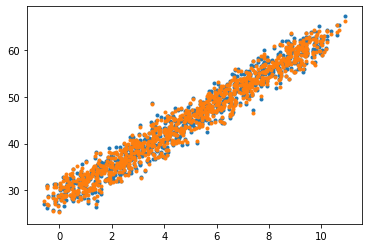

In [53]:
plot.scatter(test_x, test_z,marker='.')
plot.scatter(test_x,test_z_2,marker='.')

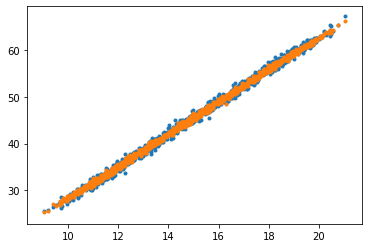

In [54]:
plot.scatter(test_y, test_z,marker='.')
plot.scatter(test_y,test_z_2,marker='.')

In [36]:
# First we need to flatten the data: it's 2D layout is not relevent.
x = test_x
y = test_y
z = test_z

data = pandas.DataFrame({'z': z, 'x': x, 'y': y})

# Fit the model
model = ols("z ~ x + y", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                      z   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.991
Method:                 Least Squares   F-statistic:                 5.323e+04
Date:                Tue, 25 Feb 2020   Prob (F-statistic):               0.00
Time:                        22:43:02   Log-Likelihood:                -1395.9
No. Observations:                1000   AIC:                             2798.
Df Residuals:                     997   BIC:                             2813.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.4083      0.458     -3.073      0.0

In [17]:
# First, let's look at all of the Fundamental mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
logMData = LimitedFundamentalPulsatorArray[logMIndex]
logRData = LimitedFundamentalPulsatorArray[logRIndex]
logPData = LimitedFundamentalPulsatorArray[logP0Index]

data = pandas.DataFrame({'logM': logMData, 'logR': logRData, 'logP0': logPData})

# Fit the model
model = ols("logP0 ~ logM + logR", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

                            OLS Regression Results                            
Dep. Variable:                  logP0   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 6.382e+04
Date:                Mon, 17 Feb 2020   Prob (F-statistic):               0.00
Time:                        01:53:51   Log-Likelihood:                 961.53
No. Observations:                 302   AIC:                            -1917.
Df Residuals:                     299   BIC:                            -1906.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.2950      0.016   -147.663      0.0

### M: logP0 = -2.295(16) - 0.879(7)logM + 2.049(7)logR

In [ ]:


# Now, let's look at all of the first overtone mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
logMData = P1Stars[logMIndex]
logRData = P1Stars[logRIndex]
logPData = P1Stars[logP1Index]

data = pandas.DataFrame({'x0': logMData, 'x1': logRData, 'y': logPData})

# Fit the model
model = ols("y ~ x0 + x1", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

M stars: logP1 = -1.211(66) - 0.302(32)logM + 1.407(32)logR

In [ ]:
# Now, let's look at all of the first overtone mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
logRData = LimitedFundamentalPulsatorArray[logRIndex]
logLData = LimitedFundamentalPulsatorArray[logLIndex]
logMData = LimitedFundamentalPulsatorArray[logMIndex]

data = pandas.DataFrame({'logL': logLData, 'logM': logMData, 'logR': logRData})

# Fit the model
model = ols("logR ~ logL + logM", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

M Stars, logM>0: logR = -0.483(30) + 0.770(9)logL - 0.353(17)logM

In [ ]:
# Now, let's look at all of the first overtone mode data at once.
# Convert the data into a Pandas DataFrame to use the formulas framework
# in statsmodels

# First we need to flatten the data: it's 2D layout is not relevent.
logRData = logRMLT005Data
logLData = logLLT005Data
logMData = logMLT005Data
logMDataSq = logMLT005Data**2

data = pandas.DataFrame({'logL': logLData, 'logM': logMData, 'logM^2':logMDataSq, 'logR': logRData})

# Fit the model
model = ols("logR ~ logM + x1 + x2", data).fit()

# Print the summary
print(model.summary())

print("\nRetrieving manually the parameter estimates:")
print(model._results.params)

# Peform analysis of variance on fitted linear model
anova_results = anova_lm(model)

print('\nANOVA results')
print(anova_results)

M Stars, logM<0: logR = -0.453(39) + 0.756(11)logL - 0.266(70)logM -0.963(423)(logM)^2
